<img src = "https://drive.google.com/uc?export=view&id=10DJdk95gzrY6H-dKEFKshN814gdMc9FV" alt = "Encabezado MLDS" width = "100%">  </img>

# **Entendimiento y Preparación de los Datos**
---

Este notebook es una plantilla que le puede servir como guía para el segundo entregable del proyecto aplicado.

## **0. Integrantes del equipo de trabajo**
---

Por favor incluya los nombres completos y número de identificación de los integrantes del equipo de trabajo:

1. ---**INGRESE SU RESPUESTA**---
2. ---**INGRESE SU RESPUESTA**---
3. ---**BRAYAN SEBASTIAN YEPES GARCIA 1015457884**---

## **1. Análisis Exploratorio de los Datos**
---

Normalmente en el análisis exploratorio, se trata de dar respuesta a los siguientes elementos:

### **1.1. Resumen General**
---

- ¿Cuántos documentos tiene el *dataset*?
- ¿En qué formato están almacenados los datos?
- ¿Qué tamaño en MB tiene el conjunto de datos?

---**INGRESE SU RESPUESTA**---

### **1.2. Resumen de la Calidad de los datos**
---

- ¿Se detecta la ausencia de datos, la presencia de documentos vacíos o la existencia de datos de baja calidad en el conjunto?
- ¿Se identifican documentos ilegibles o con dificultades de codificación durante la revisión del conjunto de datos?
- ¿Se observa una diversidad de formatos en el conjunto de datos que pueda dificultar su consistencia o comprensión?
- ¿Se identificaron y abordaron posibles problemas, como valores atípicos, duplicados o datos faltantes?

---**INGRESE SU RESPUESTA**---

### **1.3. Tipos de variables**
---

- ¿El conjunto de datos tiene una variable objetivo a estimar?, de ser así, ¿es una variable continúa o categórica?
- Analice la distribución de las etiquetas, identifique si hay desbalanceo de datos.
- ¿El conjunto de datos cuenta con otras variables adicionales?, de ser así, debe analizar cuáles se incorporarán en el modelo y hacer un análisis descriptivo de las mismas.

---**INGRESE SU RESPUESTA**---

### **1.4. Relación Entre Variables**
---

- Analice si existe alguna relación entre las variables. Puede utilizar medidas de correlación o visualizaciones.
- Identifique si hay redundancia entre las variables para una posterior eliminación o selección.

---**INGRESE SU RESPUESTA**---

## Preconteo

### Descripción y alcance del conjunto de datos

El presente análisis se desarrolla en el marco de la fase **Data Understanding** de la metodología CRISP-DM, utilizando los datos de preconteo correspondientes a la primera vuelta de las elecciones presidenciales de Colombia de 2026.

El objetivo de esta etapa es comprender la procedencia, estructura, contenido y características generales de los registros electorales antes de realizar procedimientos de preparación de datos o implementar algoritmos de Machine Learning.

El estudio se concentra en el archivo `PRE1v_MMV_9999_PRECONTEO.txt`, incluido en el paquete `MMV_Presidente1V_2026.zip`. Los demás archivos se consideran recursos documentales o auxiliares, según su función y pertinencia.

El análisis comprende:

- Identificación e inventario de las fuentes disponibles.
- Revisión de la documentación técnica oficial.
- Caracterización del formato y estructura de los registros.
- Verificación preliminar de integridad estructural.
- Identificación de patrones de codificación alfanumérica.
- Evaluación inicial de la viabilidad para construir un conjunto de datos analítico.

Esta etapa se limita a la comprensión de los datos originales. No se realizarán transformaciones irreversibles ni se interpretarán observaciones atípicas como evidencia de irregularidades electorales.

### Fuente de información e inventario de archivos

Los datos provienen de un paquete de información electoral atribuido a la Registraduría Nacional del Estado Civil de Colombia, que contiene registros de votación mesa a mesa, documentación técnica y archivos auxiliares.

Como actividad inicial de *Data Understanding*, se realiza un inventario de los recursos disponibles para identificar sus formatos, tamaños y funciones dentro del proyecto.

| Archivo | Formato | Función dentro del paquete |
|---|---|---|
| `PRE1v_MMV_9999_PRECONTEO.txt` | TXT | Archivo principal de registros de preconteo |
| `_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv` | CSV | Archivo de escrutinio, excluido del alcance analítico |
| `Estructuras Basicas (1808).pdf` | PDF | Especificaciones de campos, tipos y longitudes |
| `HASH_PRE1v_MMV_9999_PRECONTEO.txt` | TXT | Información de integridad del archivo de preconteo |
| `HASH_ficheros_MMV_4_MMV_9999_ESCRUTINIO.txt` | TXT | Información de integridad del archivo de escrutinio |
| `ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip` | ZIP | Archivos auxiliares para interpretación de códigos |
| `Novedad20260603.zip` | ZIP | Archivos complementarios de novedades, pendientes de caracterización |

Los archivos originales se conservan en `data/raw/`, sin modificaciones.

El inventario programático permite verificar la existencia física de los recursos y registrar sus tamaños. La inspección del contenido de los archivos comprimidos auxiliares se realizará posteriormente, antes de utilizarlos como fuentes de referencia.

In [17]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

DATA_DIR = Path(
    "../../data/raw/elecciones_2026/extracted/"
    "MMV_Presidente1V_2026/MMV_Presidente1V_2026"
)

PRECONTEO_PATH = DATA_DIR / "PRE1v_MMV_9999_PRECONTEO.txt"

assert DATA_DIR.is_dir(), "No se encontró el directorio de datos."
assert PRECONTEO_PATH.is_file(), "No se encontró el archivo de preconteo."

inventario = []

for archivo in sorted(DATA_DIR.iterdir()):
    if archivo.is_file():
        inventario.append({
            "Archivo": archivo.name,
            "Formato": archivo.suffix.lower(),
            "Tamaño (MiB)": round(
                archivo.stat().st_size / 1024**2, 3
            ),
        })

df_inventario = pd.DataFrame(inventario)

display(df_inventario)

,Archivo,Formato,Tamaño (MiB)
0,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip,.zip,2.044
1,Estructuras Basicas (1808).pdf,.pdf,0.165
2,HASH_PRE1v_MMV_9999_PRECONTEO.txt,.txt,0.001
3,HASH_ficheros_MMV_4_MMV_9999_ESCRUTINIO.txt,.txt,0.001
4,Novedad20260603.zip,.zip,2.020
5,PRE1v_MMV_9999_PRECONTEO.txt,.txt,56.439
6,_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv,.csv,100.541


### Documentación oficial y formato de almacenamiento

La interpretación del archivo de preconteo se fundamenta en el documento `Estructuras Basicas (1808).pdf`, incluido en el paquete electoral.

La documentación describe la organización de los archivos de votación mesa a mesa (MMV) y establece las características de almacenamiento de sus registros.

#### Formato de longitud fija

El archivo de preconteo utiliza una estructura de **ancho fijo (*fixed-width format*)**. A diferencia de un archivo CSV convencional, los campos no están separados por delimitadores, sino que ocupan posiciones predeterminadas dentro de cada registro.

La estructura documentada tiene una longitud de 38 caracteres, sin incluir los caracteres de terminación de línea.

Los registros finalizan con `CRLF`, correspondiente a retorno de carro y avance de línea.

Los campos numéricos utilizan longitudes definidas y pueden contener ceros a la izquierda. Por esta razón, los códigos administrativos deben conservarse inicialmente como cadenas de caracteres, evitando conversiones numéricas que alteren su representación.

#### Diccionario estructural de preconteo

| Campo oficial | Tipo | Longitud | Posiciones |
|---|---|---:|---|
| Código departamento | Numérico | 2 | 1–2 |
| Código municipio | Numérico | 3 | 3–5 |
| Zona | Alfanumérico | 2 | 6–7 |
| Puesto | Alfanumérico | 2 | 8–9 |
| Número de mesa | Numérico | 6 | 10–15 |
| Código JAL | Numérico | 2 | 16–17 |
| Número del comunicado | Numérico | 4 | 18–21 |
| Código de circunscripción | Numérico | 1 | 22 |
| Código de Lista o Partido | Numérico | 5 | 23–27 |
| Código de candidato | Numérico | 3 | 28–30 |
| Votos | Numérico | 8 | 31–38 |
| **Total** | | **38** | |

La documentación establece que el campo `Número del comunicado` tiene el valor `9999` para esta estructura.

#### Granularidad de los registros

Cada fila contiene información de identificación territorial y de mesa, junto con códigos electorales y una cantidad de votos.

En consecuencia, no debe suponerse que cada fila representa una mesa diferente. Una misma mesa puede estar asociada con múltiples registros electorales.

La identificación de una clave lógica y la definición de la unidad de análisis se realizarán después de cargar e inspeccionar los campos.

**Implicación metodológica:** cualquier agregación de votos por mesa o territorio deberá respetar la estructura documentada y las categorías electorales correspondientes.

### Inspección física de los registros

Antes de construir un DataFrame, se realiza una inspección directa del archivo original en modo binario.

Este procedimiento permite observar su representación física sin introducir supuestos sobre delimitadores, codificación o tipos de datos.

Se examinan los primeros registros y se verifica el tamaño del archivo. Posteriormente se analizará la consistencia de las longitudes, la presencia de registros vacíos y la duplicidad exacta.

La lectura en modo binario permite identificar explícitamente los caracteres de terminación de línea y preservar el contenido original durante la inspección.

In [18]:
print("Archivo:", PRECONTEO_PATH.name)
print("Existe:", PRECONTEO_PATH.exists())
print(
    "Tamaño (MiB):",
    round(PRECONTEO_PATH.stat().st_size / 1024**2, 2)
)

with PRECONTEO_PATH.open("rb") as archivo:
    for i in range(5):
        print(f"Registro {i + 1}:", repr(archivo.readline()))

Archivo: PRE1v_MMV_9999_PRECONTEO.txt
Existe: True
Tamaño (MiB): 56.44
Registro 1: b'01001010100000100999900000901100000027\r\n'
Registro 2: b'01001010100000100999900001501200000005\r\n'
Registro 3: b'01001010100000100999900002000600000001\r\n'
Registro 4: b'01001010100000100999900002101000000000\r\n'
Registro 5: b'01001010100000100999900002200800000000\r\n'


#### Resultados de la lectura preliminar

La inspección confirmó la existencia del archivo `PRE1v_MMV_9999_PRECONTEO.txt`, con un tamaño aproximado de **56,44 MiB**.

Los cinco registros examinados presentan una secuencia de 38 caracteres, seguida por los caracteres de terminación `\r\n`.

El resultado es compatible con el formato de longitud fija descrito en la documentación técnica.

No se identificaron encabezados ni delimitadores convencionales en los registros inspeccionados. Por tanto, la lectura posterior deberá realizarse mediante posiciones de campos y no mediante separación por comas o puntos y coma.

Esta observación inicial no permite concluir que todos los registros cumplen el formato. Para ello se realiza una verificación sobre el archivo completo.

### Perfilamiento estructural del archivo completo

Se realiza un procedimiento de *structural data profiling* para evaluar las características físicas de todos los registros.

Se consideran cinco indicadores:

- **Número de registros:** volumen total de observaciones.
- **Longitud de registros:** consistencia con la estructura de 38 caracteres.
- **Registros vacíos:** presencia de líneas sin contenido.
- **Registros con caracteres no numéricos:** identificación preliminar de valores alfanuméricos.
- **Duplicados exactos:** frecuencia de líneas con contenido idéntico.

La presencia de caracteres no numéricos no se considera automáticamente un error, debido a que la documentación oficial define campos alfanuméricos.

Asimismo, la ausencia de duplicados exactos no garantiza la unicidad lógica de los registros electorales, dado que esta depende de la identificación de una clave apropiada.

In [19]:
from collections import Counter

longitudes = Counter()
registros_vacios = 0
registros_no_numericos = 0
duplicados_exactos = 0
registros_vistos = set()
total_registros = 0

with PRECONTEO_PATH.open("rb") as archivo:
    for linea in archivo:
        registro = linea.rstrip(b"\r\n")
        total_registros += 1

        longitudes[len(registro)] += 1

        if not registro:
            registros_vacios += 1

        if not registro.isdigit():
            registros_no_numericos += 1

        if registro in registros_vistos:
            duplicados_exactos += 1
        else:
            registros_vistos.add(registro)

resumen_estructura = pd.DataFrame({
    "Indicador": [
        "Total de registros",
        "Registros de 38 caracteres",
        "Registros vacíos",
        "Registros con caracteres no numéricos",
        "Duplicados exactos"
    ],
    "Cantidad": [
        total_registros,
        longitudes[38],
        registros_vacios,
        registros_no_numericos,
        duplicados_exactos
    ]
})

resumen_estructura["Porcentaje"] = (
    100 * resumen_estructura["Cantidad"] / total_registros
)

display(resumen_estructura)
print("Distribución de longitudes:", dict(longitudes))

,Indicador,Cantidad,Porcentaje
0,Total de registros,1479506,100.000000
1,Registros de 38 caracteres,1479506,100.000000
2,Registros vacíos,0,0.000000
3,Registros con caracteres no numéricos,12517,0.846026
4,Duplicados exactos,0,0.000000


Distribución de longitudes: {38: 1479506}


#### Resultados del perfilamiento estructural

El análisis completo produjo los siguientes resultados:

| Indicador | Resultado |
|---|---:|
| Total de registros | 1.479.506 |
| Registros de 38 caracteres | 1.479.506 |
| Registros con longitud diferente | 0 |
| Registros vacíos | 0 |
| Registros con caracteres no numéricos | 12.517 |
| Registros duplicados exactos | 0 |

La totalidad de los registros presenta una longitud uniforme de 38 caracteres, lo que confirma la consistencia física del archivo respecto a la longitud establecida en la documentación.

No se identificaron registros vacíos ni líneas exactamente duplicadas.

Se encontraron **12.517 registros (aproximadamente 0,85 %)** con caracteres distintos de dígitos. Este resultado requiere examinar su ubicación dentro de la estructura antes de determinar si representa alguna inconsistencia.

En términos generales, el archivo presenta una estructura física homogénea. Sin embargo, la validación de los tipos de campos y de los códigos administrativos requiere comprobaciones adicionales.

### Validación de los campos según la documentación oficial

Una vez verificada la longitud de los registros, se contrasta su contenido con las restricciones establecidas en `Estructuras Basicas (1808).pdf`.

Esta validación examina:

- La longitud total de 38 caracteres.
- La composición numérica de los campos declarados como numéricos.
- La composición alfanumérica de los campos `Zona` y `Puesto`.
- El valor constante `9999` del campo `Número del comunicado`.

Esta comprobación evalúa el cumplimiento del esquema físico y de los tipos de datos documentados. No constituye todavía una validación completa de los dominios electorales, que requerirá consultar los archivos básicos auxiliares.

In [20]:
campos = [
    ("departamento", 2, "numerico"),
    ("municipio", 3, "numerico"),
    ("zona", 2, "alfanumerico"),
    ("puesto", 2, "alfanumerico"),
    ("mesa", 6, "numerico"),
    ("jal", 2, "numerico"),
    ("comunicado", 4, "numerico"),
    ("circunscripcion", 1, "numerico"),
    ("lista_partido", 5, "numerico"),
    ("candidato", 3, "numerico"),
    ("votos", 8, "numerico"),
]

assert sum(longitud for _, longitud, _ in campos) == 38

errores = Counter()
ejemplos_errores = []

with PRECONTEO_PATH.open("rb") as archivo:
    for numero_linea, linea in enumerate(archivo, start=1):
        registro = linea.rstrip(b"\r\n")

        if len(registro) != 38:
            errores["longitud_incorrecta"] += 1
            continue

        inicio = 0

        for nombre, longitud, tipo in campos:
            valor = registro[inicio:inicio + longitud]
            inicio += longitud

            if tipo == "numerico":
                valido = valor.isdigit()
            else:
                valido = all(
                    48 <= c <= 57 or
                    65 <= c <= 90 or
                    97 <= c <= 122
                    for c in valor
                )

            if not valido:
                errores[f"tipo_invalido_{nombre}"] += 1

                if len(ejemplos_errores) < 10:
                    ejemplos_errores.append(
                        (numero_linea, nombre, repr(valor))
                    )

        if registro[17:21] != b"9999":
            errores["comunicado_incorrecto"] += 1

print("Inconsistencias por regla:", dict(errores))
print("Ejemplos:", ejemplos_errores)

Inconsistencias por regla: {}
Ejemplos: []


#### Interpretación de la validación estructural

La validación del esquema oficial permite determinar si los registros cumplen las restricciones de longitud, tipo de campo y valor constante del comunicado.

La ausencia de incumplimientos en estas comprobaciones indicaría que el archivo es estructuralmente compatible con el formato documentado por la Registraduría.

No obstante, esta validación no garantiza que todos los códigos de departamento, municipio, zona, puesto, partido o candidato correspondan a valores reconocidos en los catálogos oficiales.

La evaluación de esos dominios se realizará en la etapa de calidad de los datos, mediante el contraste con los archivos auxiliares disponibles.

### Caracterización de los campos alfanuméricos

Durante el perfilamiento inicial se identificaron 12.517 registros con caracteres diferentes de dígitos.

La documentación oficial establece que los campos `Zona` y `Puesto` son alfanuméricos. Por tanto, resulta necesario estudiar la ubicación y frecuencia de estos caracteres para verificar su correspondencia con las posiciones documentadas.

Se analizarán las frecuencias de cada carácter, sus posiciones dentro del registro y ejemplos de las observaciones identificadas.

Este procedimiento permite diferenciar características legítimas del formato de posibles inconsistencias de codificación.

In [21]:
caracteres = Counter()
posiciones = Counter()
ejemplos = []

with PRECONTEO_PATH.open("rb") as archivo:
    for numero_linea, linea in enumerate(archivo, start=1):
        registro = linea.rstrip(b"\r\n")

        if not registro.isdigit():
            if len(ejemplos) < 10:
                ejemplos.append((
                    numero_linea,
                    registro.decode("ascii", errors="replace")
                ))

            for posicion, caracter in enumerate(registro, start=1):
                if not (48 <= caracter <= 57):
                    caracteres[chr(caracter)] += 1
                    posiciones[posicion] += 1

df_caracteres = pd.DataFrame(
    caracteres.items(),
    columns=["Carácter", "Frecuencia"]
).sort_values("Frecuencia", ascending=False)

df_posiciones = pd.DataFrame(
    posiciones.items(),
    columns=["Posición", "Frecuencia"]
).sort_values("Posición")

display(df_caracteres)
display(df_posiciones)

print("Ejemplos:")
for numero, registro in ejemplos:
    print(f"Línea {numero}: {registro}")

,Carácter,Frecuencia
0,A,6074
1,B,3941
2,C,524
3,D,448
4,E,192
22,W,144
14,P,116
17,R,102
24,Y,96
7,H,96


,Posición,Frecuencia
0,8,12517
1,9,16


Ejemplos:
Línea 79745: 0100199A100000100999900000901100000032
Línea 79746: 0100199A100000100999900001501200000009
Línea 79747: 0100199A100000100999900002000600000001
Línea 79748: 0100199A100000100999900002101000000000
Línea 79749: 0100199A100000100999900002200800000000
Línea 79750: 0100199A100000100999900002600100000029
Línea 79751: 0100199A100000100999900000099600000000
Línea 79752: 0100199A100000100999900000099700000002
Línea 79753: 0100199A100000100999900000099800000004
Línea 79754: 0100199A100000100999900100100300000001


#### Resultados de la caracterización alfanumérica

El análisis identificó 12.517 registros con caracteres alfabéticos, equivalentes aproximadamente al 0,85 % del conjunto de datos.

Se encontraron 26 letras mayúsculas diferentes. Las más frecuentes fueron `A` (6.074 apariciones) y `B` (3.941 apariciones).

Los caracteres se localizaron exclusivamente en las posiciones 8 y 9:

| Posición | Apariciones |
|---|---:|
| 8 | 12.517 |
| 9 | 16 |

De acuerdo con la estructura oficial, ambas posiciones pertenecen al campo `Puesto`, cuya longitud es de dos caracteres y cuyo tipo es alfanumérico.

Por consiguiente, la presencia de letras en estas posiciones **es compatible con la especificación del archivo y no representa por sí misma un error de calidad**.

Este resultado evidencia la importancia de conservar los códigos administrativos como cadenas de caracteres y utilizar la documentación técnica para interpretar los datos.

La validación de los códigos concretos de puesto frente a los catálogos oficiales permanece pendiente.

### Interpretación de un registro mediante las posiciones oficiales

Para ilustrar la estructura del archivo, se selecciona un registro real que contiene un código de puesto alfanumérico.

El registro se divide utilizando las longitudes establecidas en la documentación oficial. Este procedimiento permite observar cómo se encuentran representados los campos sin alterar los datos originales.

La segmentación también sirve como comprobación preliminar del procedimiento que se utilizará posteriormente para construir el DataFrame.

In [22]:
registro = "0100199A100000100999900000901100000032"

inicio = 0
segmentos = []

for nombre, longitud, tipo in campos:
    valor = registro[inicio:inicio + longitud]

    segmentos.append({
        "Campo": nombre,
        "Posición inicial": inicio + 1,
        "Posición final": inicio + longitud,
        "Valor": valor,
        "Tipo oficial": tipo,
    })

    inicio += longitud

df_segmentos = pd.DataFrame(segmentos)

display(df_segmentos)

,Campo,Posición inicial,Posición final,Valor,Tipo oficial
0,departamento,1,2,01,numerico
1,municipio,3,5,001,numerico
2,zona,6,7,99,alfanumerico
3,puesto,8,9,A1,alfanumerico
4,mesa,10,15,000001,numerico
5,jal,16,17,00,numerico
6,comunicado,18,21,9999,numerico
7,circunscripcion,22,22,0,numerico
8,lista_partido,23,27,00009,numerico
9,candidato,28,30,011,numerico


### Conclusiones de la caracterización estructural

La revisión documental y el análisis preliminar del archivo de preconteo permiten establecer los siguientes hallazgos:

- El archivo contiene **1.479.506 registros** de longitud fija, cada uno con 38 caracteres.
- No se identificaron registros vacíos ni duplicados exactos.
- La estructura observada es consistente con las longitudes especificadas en la documentación oficial.
- Los 12.517 registros que contienen caracteres alfabéticos presentan dichos caracteres en posiciones correspondientes al campo `Puesto`, definido como alfanumérico.
- Los registros contienen información territorial, identificadores electorales y cantidades de votos, pero todavía no se ha determinado la clave lógica que identifica cada observación.

En consecuencia, la inspección inicial proporciona evidencia favorable sobre la consistencia física del archivo, aunque todavía no permite concluir que los datos estén completamente libres de errores.

#### Aspectos pendientes

Para continuar con *Data Understanding* será necesario construir una representación tabular de los registros, identificar las categorías y dominios de cada campo, examinar los catálogos auxiliares y determinar la granularidad apropiada para el análisis electoral.

Estas actividades permitirán avanzar hacia el estudio de distribuciones, calidad de datos y relaciones entre variables, manteniendo la trazabilidad respecto de los archivos originales.

### Construcción de la representación tabular

Una vez comprobada la estructura física del archivo de preconteo, se procede a construir una representación tabular utilizando `pandas`.

La transformación consiste en segmentar cada registro de 38 caracteres según las posiciones y longitudes establecidas en la documentación oficial. Esta operación no modifica los archivos originales y permite analizar los campos de manera independiente.

Inicialmente, todas las variables se conservarán como cadenas de caracteres. Esta decisión es especialmente importante para los códigos administrativos y electorales, cuyos ceros iniciales forman parte de su representación.

Posteriormente, el campo `votos` se convertirá a un tipo entero, previa verificación de su composición numérica.

La construcción del DataFrame constituye una transformación de representación necesaria para la exploración, pero no implica todavía limpieza, eliminación de registros, agregación territorial ni ingeniería de características.

### Construcción y caracterización del conjunto de datos

Una vez verificada la estructura física del archivo de preconteo y su correspondencia con la documentación técnica, se procede a construir una representación tabular mediante la biblioteca `pandas`.

El objetivo de este procedimiento es identificar las dimensiones del

In [25]:
import pandas as pd

nombres_columnas = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
    "jal",
    "comunicado",
    "circunscripcion",
    "lista_partido",
    "candidato",
    "votos",
]

longitudes = [2, 3, 2, 2, 6, 2, 4, 1, 5, 3, 8]

limites = [0]

for longitud in longitudes:
    limites.append(limites[-1] + longitud)

colspecs = list(zip(limites[:-1], limites[1:]))

df_preconteo = pd.read_fwf(
    PRECONTEO_PATH,
    colspecs=colspecs,
    names=nombres_columnas,
    dtype="string",
    header=None,
    keep_default_na=False,
)

assert len(df_preconteo) == total_registros
assert df_preconteo.shape[1] == 11

df_preconteo["votos"] = pd.to_numeric(
    df_preconteo["votos"],
    errors="raise",
).astype("int64")

print("Dimensiones:", df_preconteo.shape)
display(df_preconteo.head(10))

Dimensiones: (1479506, 11)


,departamento,municipio,zona,puesto,mesa,jal,comunicado,circunscripcion,lista_partido,candidato,votos
0,01,001,01,01,000001,00,9999,0,00009,011,27
1,01,001,01,01,000001,00,9999,0,00015,012,5
2,01,001,01,01,000001,00,9999,0,00020,006,1
3,01,001,01,01,000001,00,9999,0,00021,010,0
4,01,001,01,01,000001,00,9999,0,00022,008,0
5,01,001,01,01,000001,00,9999,0,00026,001,30
6,01,001,01,01,000001,00,9999,0,00000,996,3
7,01,001,01,01,000001,00,9999,0,00000,997,0
8,01,001,01,01,000001,00,9999,0,00000,998,1
9,01,001,01,01,000001,00,9999,0,01001,003,0


### Verificación de la representación tabular

Después de cargar el archivo, se verifica que el número de observaciones coincida con el obtenido durante la inspección física y que la representación contenga los once campos establecidos en la documentación oficial.

También se revisan los primeros registros para comprobar que los valores fueron segmentados correctamente y que los códigos conservan su longitud y sus ceros iniciales.

El campo `votos` se representa como una cantidad entera, mientras que los demás campos permanecen como cadenas de caracteres.

Esta verificación es necesaria para evitar errores de interpretación que podrían propagarse a los análisis descriptivos y a las fases posteriores de Machine Learning.

### Caracterización de variables y cardinalidad

El análisis de variables permite identificar las características generales de los campos disponibles y evaluar su posible utilidad para el problema de investigación.

Se distinguen tres tipos conceptuales de variables:

- **Identificadores administrativos y electorales:** códigos que permiten localizar o relacionar registros, pero que no representan magnitudes cuantitativas.
- **Variables categóricas:** campos que identifican clases, agrupaciones o modalidades electorales.
- **Variables cuantitativas:** cantidades numéricas sobre las cuales pueden realizarse operaciones aritméticas, como el número de votos.

Se calculará la cardinalidad de cada variable, entendida como el número de valores distintos presentes en el conjunto de datos.

También se verificará la presencia de valores vacíos y la longitud de los códigos, como parte de la evaluación preliminar de completitud y consistencia.

Una cardinalidad elevada no constituye necesariamente un problema de calidad. En campos identificadores puede ser una característica esperada de su función.

In [27]:
perfil = []

for columna in df_preconteo.columns:
    serie = df_preconteo[columna]

    perfil.append({
        "Variable": columna,
        "Tipo pandas": str(serie.dtype),
        "Valores únicos": serie.nunique(dropna=True),
        "Valores nulos": serie.isna().sum(),
        "Valores vacíos": (
            serie.eq("").sum()
            if pd.api.types.is_string_dtype(serie)
            else 0
        ),
    })

df_perfil = pd.DataFrame(perfil)

display(df_perfil)

print("\nTipos de datos:")
df_preconteo.info(
    memory_usage="deep",
    show_counts=True
)

,Variable,Tipo pandas,Valores únicos,Valores nulos,Valores vacíos
0,departamento,string,34,0,0
1,municipio,string,309,0,0
2,zona,string,52,0,0
3,puesto,string,208,0,0
4,mesa,string,228,0,0
5,jal,string,1,0,0
6,comunicado,string,1,0,0
7,circunscripcion,string,1,0,0
8,lista_partido,string,14,0,0
9,candidato,string,16,0,0



Tipos de datos:
<class 'pandas.DataFrame'>
RangeIndex: 1479506 entries, 0 to 1479505
Data columns (total 11 columns):
 #   Column           Non-Null Count    Dtype 
---  ------           --------------    ----- 
 0   departamento     1479506 non-null  string
 1   municipio        1479506 non-null  string
 2   zona             1479506 non-null  string
 3   puesto           1479506 non-null  string
 4   mesa             1479506 non-null  string
 5   jal              1479506 non-null  string
 6   comunicado       1479506 non-null  string
 7   circunscripcion  1479506 non-null  string
 8   lista_partido    1479506 non-null  string
 9   candidato        1479506 non-null  string
 10  votos            1479506 non-null  int64 
dtypes: int64(1), string(10)
memory usage: 745.0 MB


### Identificación de la unidad de observación

Determinar la granularidad del conjunto de datos es indispensable para realizar análisis estadísticos válidos.

La documentación establece que los registros contienen identificadores territoriales, de mesa y de opciones electorales. Sin embargo, la presencia de un identificador de mesa no implica que exista una sola fila por mesa.

Se estudiará la cantidad de combinaciones únicas de departamento, municipio, zona, puesto y mesa, así como el número de registros asociados a cada combinación.

Adicionalmente, se examinará la unicidad de una clave compuesta que incluya los campos electorales disponibles. Esta comprobación permitirá identificar posibles registros repetidos a nivel lógico, sin asumir previamente que una combinación específica constituye una clave primaria definitiva.

La determinación de la granularidad será fundamental para evitar pseudorreplicación, agregaciones incorrectas y problemas de *data leakage* en etapas posteriores.

In [28]:
columnas_mesa = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
]

columnas_clave_candidata = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
    "jal",
    "comunicado",
    "circunscripcion",
    "lista_partido",
    "candidato",
]

total_mesas = (
    df_preconteo[columnas_mesa]
    .drop_duplicates()
    .shape[0]
)

duplicados_clave = df_preconteo.duplicated(
    subset=columnas_clave_candidata
).sum()

registros_por_mesa = (
    df_preconteo
    .groupby(columnas_mesa, dropna=False)
    .size()
    .rename("n_registros")
    .reset_index()
)

print(f"Registros totales: {len(df_preconteo):,}")
print(f"Combinaciones de mesa: {total_mesas:,}")
print(f"Duplicados de clave candidata: {duplicados_clave:,}")

print("\nDistribución de registros por mesa:")
display(
    registros_por_mesa["n_registros"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99])
    .to_frame()
)

Registros totales: 1,479,506
Combinaciones de mesa: 122,020
Duplicados de clave candidata: 0

Distribución de registros por mesa:


,n_registros
count,122020.000000
mean,12.125111
std,4.055918
min,1.000000
25%,8.000000
50%,13.000000
75%,16.000000
90%,16.000000
95%,16.000000
99%,16.000000


#### Resultados de la representación tabular y granularidad

La lectura del archivo de preconteo produjo un DataFrame de **1.479.506 observaciones y 11 variables**, coincidente con el volumen de registros identificado durante la inspección física.

Diez variables se conservaron como cadenas de caracteres (`string`), mientras que `votos` se representó mediante enteros de 64 bits (`int64`). Esta separación permite preservar los identificadores administrativos y realizar operaciones aritméticas sobre las cantidades de votos.

La representación tabular ocupa aproximadamente **745 MB de memoria**, según el cálculo de uso profundo de memoria de pandas.

Al examinar las combinaciones de departamento, municipio, zona, puesto y mesa, se identificaron **122.020 combinaciones distintas**, con un promedio aproximado de **12,13 registros por combinación**.

Esto confirma que la unidad de observación del archivo no corresponde a una mesa electoral única, sino a registros más detallados asociados con mesas y códigos electorales.

Adicionalmente, no se encontraron duplicados bajo la clave compuesta candidata que incluye los identificadores territoriales, de mesa y de opción electoral.

**Implicación metodológica**

La ausencia de duplicados bajo esta clave constituye evidencia favorable sobre la unicidad de los registros, pero no demuestra por sí sola que la clave sea la definición oficial de identificación.

Antes de construir variables agregadas por mesa, será necesario comprender los códigos electorales, verificar los catálogos auxiliares y estudiar la distribución de registros por mesa.

### Distribución de registros por mesa electoral

Una vez identificadas las combinaciones únicas de mesa, se analiza el número de registros asociados a cada una.

Este análisis permite estudiar la heterogeneidad de la representación de las mesas dentro del archivo de preconteo e identificar posibles diferencias en la cantidad de registros electorales asociados a ellas.

Se calcularán medidas de tendencia central y dispersión, incluyendo media, mediana, desviación estándar, valores extremos y cuantiles.

Posteriormente, se utilizarán un histograma y un diagrama de caja (*boxplot*) para examinar la distribución.

Es importante señalar que una cantidad inusual de registros por mesa no constituye automáticamente una anomalía electoral. Su interpretación requiere conocer las reglas de generación de registros y las categorías electorales incluidas.

,Registros por mesa
count,122020.000000
mean,12.125111
std,4.055918
min,1.000000
1%,4.000000
5%,6.000000
25%,8.000000
50%,13.000000
75%,16.000000
95%,16.000000


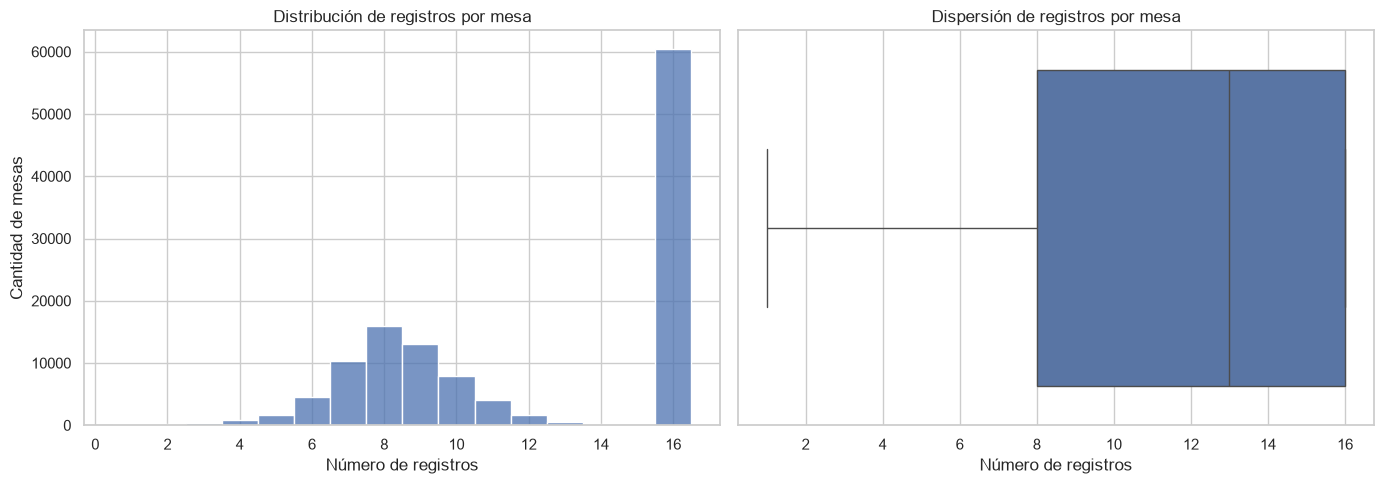

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

conteos = registros_por_mesa["n_registros"]

display(
    conteos.describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).to_frame("Registros por mesa")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    conteos,
    discrete=True,
    ax=axes[0],
)

axes[0].set_title("Distribución de registros por mesa")
axes[0].set_xlabel("Número de registros")
axes[0].set_ylabel("Cantidad de mesas")

sns.boxplot(
    x=conteos,
    ax=axes[1],
)

axes[1].set_title("Dispersión de registros por mesa")
axes[1].set_xlabel("Número de registros")

plt.tight_layout()
plt.show()

#### Interpretación de la distribución de registros por mesa

El conjunto de preconteo contiene 122.020 combinaciones únicas de mesa electoral, con un promedio de 12,13 registros por mesa y una desviación estándar de 4,06.

La mediana es de 13 registros, mientras que el primer y tercer cuartil corresponden a 8 y 16 registros, respectivamente. Esto indica que la mitad central de las mesas presenta entre 8 y 16 registros.

Se observa un mínimo de 1 registro y un máximo de 16. Además, los percentiles 75, 95 y 99 coinciden en 16 registros, lo cual evidencia una concentración de observaciones en la parte superior de la distribución.

Estos resultados confirman que el número de registros asociados a cada mesa es variable. Sin embargo, esta variabilidad no puede interpretarse directamente como una inconsistencia, dado que todavía no se han caracterizado completamente los códigos de candidato, lista y las reglas de inclusión de registros.

La distribución observada constituye un punto de partida para investigar la estructura electoral de los registros y determinar la unidad de análisis apropiada para etapas posteriores.

### Frecuencia de registros por mesa y composición electoral

Para profundizar en la granularidad del conjunto de datos, se examina la frecuencia de mesas según su número de registros y se comparan los códigos electorales presentes en mesas con diferentes cantidades de observaciones.

Este análisis busca identificar patrones de representación asociados a los campos `lista_partido`, `candidato` y `circunscripcion`.

El propósito es establecer si las diferencias observadas en el número de registros por mesa se relacionan con la composición de las opciones electorales registradas.

No se asumirá que la ausencia de un código equivale a cero votos hasta verificar las reglas de generación del archivo.

In [30]:
frecuencias = (
    registros_por_mesa["n_registros"]
    .value_counts()
    .sort_index()
    .rename_axis("Registros por mesa")
    .reset_index(name="Cantidad de mesas")
)

frecuencias["Porcentaje"] = (
    100 * frecuencias["Cantidad de mesas"] / total_mesas
).round(2)

display(frecuencias)

,Registros por mesa,Cantidad de mesas,Porcentaje
0,1,167,0.14
1,2,228,0.19
2,3,412,0.34
3,4,832,0.68
4,5,1720,1.41
5,6,4514,3.70
6,7,10247,8.40
7,8,15954,13.07
8,9,13012,10.66
9,10,7906,6.48


In [31]:
# Cardinalidad y valores más frecuentes de códigos electorales
for columna in [
    "circunscripcion",
    "lista_partido",
    "candidato",
    "jal",
    "comunicado",
]:
    print(f"\n{columna}")
    print("Valores distintos:", df_preconteo[columna].nunique())

    display(
        df_preconteo[columna]
        .value_counts()
        .head(20)
        .to_frame("Frecuencia")
    )


circunscripcion
Valores distintos: 1


,Frecuencia
circunscripcion,
0,1479506



lista_partido
Valores distintos: 14


,Frecuencia
lista_partido,
00000,302867
00026,121967
01003,121597
00009,120346
00015,117646
01004,106109
01001,102972
03001,78894
00020,73312



candidato
Valores distintos: 16


,Frecuencia
candidato,
001,121967
004,121597
011,120346
012,117646
996,117243
997,109397
002,106109
003,102972
005,78894



jal
Valores distintos: 1


,Frecuencia
jal,
00,1479506



comunicado
Valores distintos: 1


,Frecuencia
comunicado,
9999,1479506


#### Resultados de la caracterización de códigos electorales

El análisis de frecuencias identificó una estructura heterogénea en el número de registros asociados a cada mesa electoral.

De las 122.020 combinaciones de mesa, 60.397 presentan exactamente 16 registros, equivalentes al 49,50 % del total. Las demás combinaciones presentan entre 1 y 15 registros.

En cuanto a los campos electorales, se identificaron 14 valores distintos en `lista_partido` y 16 en `candidato`. Esta cardinalidad sugiere una estructura de registros asociada con un conjunto limitado de opciones electorales.

Adicionalmente, las variables `circunscripcion`, `jal` y `comunicado` presentan un único valor en todas las observaciones. Por tanto, no contienen variabilidad que pueda utilizarse directamente como información predictiva dentro de este archivo.

La presencia de códigos especiales como `996`, `997` y `998` requiere una interpretación respaldada por los archivos oficiales auxiliares.

Finalmente, aunque el máximo de registros por mesa coincide con la cardinalidad del campo `candidato`, es necesario examinar las combinaciones entre `lista_partido` y `candidato` antes de establecer la granularidad electoral definitiva.

### Relación entre códigos de lista y candidato

Para comprender la organización de los registros electorales, se estudia la relación entre los campos `lista_partido` y `candidato`.

El análisis busca identificar las combinaciones distintas de ambos códigos y determinar si existe una correspondencia estable entre ellos.

También se verificará si una misma mesa contiene registros repetidos para una combinación electoral específica.

Esta evaluación permitirá avanzar en la identificación de la clave lógica del conjunto de datos y establecer una base para futuras agregaciones.

Los resultados describirán las relaciones observadas entre códigos, sin atribuirles todavía nombres de candidatos o categorías de votación no confirmados documentalmente.

In [32]:
combinaciones_electorales = (
    df_preconteo
    .groupby(
        ["lista_partido", "candidato"],
        dropna=False
    )
    .agg(
        registros=("votos", "size"),
        mesas_con_registro=("mesa", "size")
    )
    .reset_index()
    .drop(columns="mesas_con_registro")
    .sort_values(
        ["lista_partido", "candidato"]
    )
)

print(
    "Combinaciones electorales distintas:",
    len(combinaciones_electorales)
)

display(combinaciones_electorales)

Combinaciones electorales distintas: 16


,lista_partido,candidato,registros
0,00000,996,117243
1,00000,997,109397
2,00000,998,76227
3,00009,011,120346
4,00015,012,117646
5,00020,006,73312
6,00021,010,63261
7,00022,008,67626
8,00026,001,121967
9,01001,003,102972


In [33]:
clave_mesa_opcion = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
    "lista_partido",
    "candidato",
]

duplicados_mesa_opcion = df_preconteo.duplicated(
    subset=clave_mesa_opcion,
    keep=False
)

print(
    "Registros con combinación mesa-opción repetida:",
    duplicados_mesa_opcion.sum()
)

if duplicados_mesa_opcion.any():
    display(
        df_preconteo.loc[
            duplicados_mesa_opcion,
            clave_mesa_opcion + ["votos"]
        ].sort_values(clave_mesa_opcion).head(20)
    )

Registros con combinación mesa-opción repetida: 0


In [34]:
opciones_por_mesa = (
    df_preconteo
    .groupby(columnas_mesa)
    .agg(
        registros=("votos", "size"),
        candidatos_distintos=("candidato", "nunique"),
        listas_distintas=("lista_partido", "nunique"),
    )
    .reset_index()
)

display(
    opciones_por_mesa[
        [
            "registros",
            "candidatos_distintos",
            "listas_distintas"
        ]
    ].describe()
)

print(
    "Mesas donde registros != candidatos distintos:",
    (
        opciones_por_mesa["registros"]
        != opciones_por_mesa["candidatos_distintos"]
    ).sum()
)

,registros,candidatos_distintos,listas_distintas
count,122020.000000,122020.000000,122020.000000
mean,12.125111,12.125111,10.626619
std,4.055918,4.055918,3.517905
min,1.000000,1.000000,1.000000
25%,8.000000,8.000000,7.000000
50%,13.000000,13.000000,11.000000
75%,16.000000,16.000000,14.000000
max,16.000000,16.000000,14.000000


Mesas donde registros != candidatos distintos: 0


In [35]:
clave_registro = [
    "departamento",
    "municipio",
    "zona",
    "puesto",
    "mesa",
    "candidato",
]

### Identificación de la granularidad electoral

El análisis de las combinaciones entre `lista_partido` y `candidato` identificó 16 opciones electorales distintas en el archivo de preconteo.

Se verificó que cada combinación de mesa y opción electoral aparece como máximo una vez. Asimismo, para las 122.020 combinaciones únicas de mesa, el número de registros coincide exactamente con la cantidad de códigos de candidato distintos.

Estos resultados permiten caracterizar la unidad de observación como un **registro de votos asociado a una opción electoral específica dentro de una mesa**.

En consecuencia, la combinación de departamento, municipio, zona, puesto, mesa y candidato constituye una clave lógica única observada para este conjunto de datos.

La distribución del número de opciones registradas por mesa no es uniforme: 60.397 mesas, equivalentes al 49,50 %, contienen las 16 opciones identificadas, mientras que las restantes presentan entre 1 y 15.

La ausencia de determinadas opciones en una mesa no debe interpretarse automáticamente como un error o como un valor de cero votos. Para determinar su significado será necesario contrastar las reglas de generación de registros con la documentación electoral.

Esta caracterización establece una base para la construcción posterior de una representación a nivel de mesa, apropiada para estudiar distribuciones de votación y desarrollar métodos de detección de anomalías.

### Presencia de opciones electorales y registros con cero votos

La identificación de 16 opciones electorales permite investigar la completitud de las combinaciones mesa-opción.

Aunque todas las opciones aparecen en el conjunto de datos, no todas están representadas en cada mesa. Adicionalmente, la inspección inicial confirma que existen registros explícitos con cero votos.

Por tanto, es necesario distinguir entre dos situaciones:

- Una opción electoral presente en una mesa con `votos = 0`.
- Una opción electoral sin registro asociado a esa mesa.

Estas situaciones son distintas desde el punto de vista de la representación de los datos y no deben equipararse sin una justificación documental.

Se calculará la frecuencia de aparición de cada opción electoral, la proporción de registros con cero votos y el número de mesas donde cada opción no aparece.

El análisis permitirá identificar patrones de representación y formular hipótesis sobre la estructura del archivo, sin atribuir automáticamente las ausencias a errores de captura o a resultados electorales nulos.

In [36]:
resumen_opciones = (
    df_preconteo
    .groupby(["lista_partido", "candidato"])
    .agg(
        mesas_presentes=("votos", "size"),
        registros_cero=("votos", lambda s: (s == 0).sum()),
        votos_minimos=("votos", "min"),
        votos_maximos=("votos", "max"),
        votos_mediana=("votos", "median"),
    )
    .reset_index()
)

resumen_opciones["mesas_ausentes"] = (
    total_mesas - resumen_opciones["mesas_presentes"]
)

resumen_opciones["porcentaje_presencia"] = (
    100 * resumen_opciones["mesas_presentes"] / total_mesas
).round(2)

resumen_opciones["porcentaje_ceros"] = (
    100
    * resumen_opciones["registros_cero"]
    / resumen_opciones["mesas_presentes"]
).round(2)

display(
    resumen_opciones.sort_values(
        "porcentaje_presencia",
        ascending=False
    )
)

,lista_partido,candidato,mesas_presentes,registros_cero,votos_minimos,votos_maximos,votos_mediana,mesas_ausentes,porcentaje_presencia,porcentaje_ceros
8,00026,001,121967,100,0,325,75.0,53,99.96,0.08
11,01003,004,121597,260,0,694,77.0,423,99.65,0.21
3,00009,011,120346,4255,0,139,10.0,1674,98.63,3.54
4,00015,012,117646,9046,0,98,6.0,4374,96.42,7.69
0,00000,996,117243,10113,0,70,3.0,4777,96.09,8.63
1,00000,997,109397,22753,0,111,2.0,12623,89.65,20.80
12,01004,002,106109,34606,0,245,1.0,15911,86.96,32.61
9,01001,003,102972,23425,0,179,1.0,19048,84.39,22.75
15,03001,005,78894,46567,0,136,0.0,43126,64.66,59.02
2,00000,998,76227,47450,0,227,0.0,45793,62.47,62.25


In [37]:
resumen_mesas = (
    df_preconteo
    .groupby(columnas_mesa)
    .agg(
        opciones_presentes=("candidato", "nunique"),
        suma_votos_registrados=("votos", "sum"),
        registros_cero=("votos", lambda s: (s == 0).sum()),
    )
    .reset_index()
)

resumen_por_cantidad_opciones = (
    resumen_mesas
    .groupby("opciones_presentes")
    .agg(
        cantidad_mesas=("mesa", "size"),
        mediana_votos=("suma_votos_registrados", "median"),
        promedio_votos=("suma_votos_registrados", "mean"),
        mediana_ceros=("registros_cero", "median"),
    )
    .reset_index()
)

display(resumen_por_cantidad_opciones)

,opciones_presentes,cantidad_mesas,mediana_votos,promedio_votos,mediana_ceros
0,1,167,50.0,67.688623,0.0
1,2,228,37.0,63.486842,0.0
2,3,412,31.0,54.361650,0.0
3,4,832,41.0,65.704327,0.0
4,5,1720,96.0,117.150581,0.0
5,6,4514,178.0,173.283784,0.0
6,7,10247,203.0,198.128428,0.0
7,8,15954,219.0,215.397894,0.0
8,9,13012,230.0,226.909007,0.0
9,10,7906,239.0,235.633443,0.0


#### Interpretación de la presencia de opciones electorales y los registros con cero votos

El análisis de las 16 opciones electorales evidencia diferencias considerables en su frecuencia de aparición dentro de las 122.020 combinaciones de mesa.

La opción identificada mediante el código `001` presenta la mayor cobertura, con registros en el 99,96 % de las mesas. Por el contrario, la opción `010` aparece en el 51,84 % de las mesas.

También se observa una relación descriptiva entre la frecuencia de aparición de las opciones y la proporción de registros con cero votos. Algunas opciones con menor cobertura presentan porcentajes de cero superiores al 80 %, mientras que las opciones de mayor presencia registran proporciones considerablemente menores.

Por otra parte, las mesas con 16 opciones presentan una mediana de nueve registros con cero votos, mientras que las mesas con entre una y catorce opciones presentan una mediana de cero.

Este contraste sugiere que la representación de opciones electorales podría responder a diferentes reglas de inclusión de registros. Sin embargo, los resultados no permiten determinar por sí solos cuáles son dichas reglas.

La relación entre el número de opciones presentes y la suma de votos registrados tampoco es estrictamente creciente. Las mesas con 16 opciones presentan una mediana de 188 votos, inferior a la observada en varios grupos con menos opciones.

Estos hallazgos justifican una investigación adicional sobre la estructura de los registros, particularmente sobre la coexistencia de valores explícitos de cero y opciones ausentes.

Las diferencias observadas no deben interpretarse como anomalías electorales sin verificar previamente la documentación y los mecanismos de producción del archivo.

### Análisis de patrones de presencia y ausencia de opciones electorales

El archivo de preconteo presenta una estructura de hasta 16 opciones electorales por mesa, pero no todas las opciones aparecen en todas las mesas.

Adicionalmente, los resultados muestran que existen registros explícitos con cero votos y diferencias considerables en la cantidad de opciones registradas.

Para profundizar en este comportamiento, se construirá una matriz binaria de presencia de opciones electorales por mesa.

Cada fila representará una combinación única de mesa y cada columna una opción electoral. El valor uno indicará que existe un registro para esa opción, mientras que el valor cero indicará que no existe una fila correspondiente en el archivo original.

Esta matriz describe exclusivamente la presencia de registros y no debe confundirse con una matriz de votos. En particular, una ausencia de registro no se interpretará como cero votos.

In [38]:
matriz_presencia = (
    df_preconteo
    .assign(presente=1)
    .pivot_table(
        index=columnas_mesa,
        columns="candidato",
        values="presente",
        aggfunc="max",
        fill_value=0
    )
    .astype("int8")
)

print("Dimensiones:", matriz_presencia.shape)

display(matriz_presencia.head())

Dimensiones: (122020, 16)


candidato                                  001  002  003  004  005  006  007  \
departamento municipio zona puesto mesa                                        
01           001       01   01     000001    1    1    1    1    1    1    1   
                                   000002    1    1    1    1    1    1    1   
                                   000003    1    1    1    1    1    1    1   
                                   000004    1    1    1    1    1    1    1   
                                   000005    1    1    1    1    1    1    1   

candidato                                  008  009  010  011  012  013  996  \
departamento municipio zona puesto mesa                                        
01           001       01   01     000001    1    1    1    1    1    1    1   
                                   000002    1    1    1    1    1    1    1   
                                   000003    1    1    1    1    1    1    1   
                                   000004    1    1    1    1    1    1    1   
                                   000005    1    1    1    1    1    1    1   

candidato                                  997  998  
departamento municipio zona puesto mesa              
01           001       01   01     000001    1    1  
                                   000002    1    1  
                                   000003    1    1  
                                   000004    1    1  
                                   000005    1    1

In [39]:
patrones = (
    matriz_presencia
    .value_counts()
    .rename("cantidad_mesas")
    .reset_index()
    .sort_values("cantidad_mesas", ascending=False)
)

patrones["porcentaje"] = (
    100 * patrones["cantidad_mesas"] / total_mesas
).round(2)

print("Patrones distintos:", len(patrones))

display(patrones.head(15))

Patrones distintos: 2766


,001,002,003,004,005,006,007,008,009,010,011,012,013,996,997,998,cantidad_mesas,porcentaje
0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,60397,49.50
1,1,1,1,1,0,0,0,0,0,0,1,1,0,1,1,0,7263,5.95
2,1,0,1,1,0,0,0,0,0,0,1,1,0,1,1,0,2559,2.10
3,1,1,1,1,1,0,0,0,0,0,1,1,0,1,1,0,2549,2.09
4,1,1,0,1,0,0,0,0,0,0,1,1,0,1,1,0,2105,1.73
5,1,1,1,1,0,0,0,0,0,0,1,1,0,1,0,0,1702,1.39
6,1,1,1,1,0,0,0,0,0,0,1,1,0,1,1,1,1443,1.18
7,1,1,0,1,0,0,0,0,0,0,1,1,0,1,0,0,1377,1.13
8,1,1,1,1,0,1,0,0,0,0,1,1,0,1,1,0,1193,0.98
9,1,1,1,1,0,0,1,0,0,0,1,1,0,1,1,0,864,0.71


In [40]:
comparacion = (
    resumen_mesas
    .assign(
        grupo=lambda x: np.where(
            x["opciones_presentes"] == 16,
            "16 opciones",
            "Menos de 16 opciones"
        )
    )
    .groupby("grupo")
    .agg(
        mesas=("mesa", "size"),
        mediana_votos=("suma_votos_registrados", "median"),
        mediana_ceros=("registros_cero", "median"),
        promedio_ceros=("registros_cero", "mean")
    )
)

display(comparacion)

,mesas,mediana_votos,mediana_ceros,promedio_ceros
grupo,,,,
16 opciones,60397,188.0,9.0,8.656986
Menos de 16 opciones,61623,220.0,0.0,0.074079


### Identificación de catálogos y archivos auxiliares

El análisis estructural permitió identificar 16 combinaciones únicas de códigos electorales, definidas mediante los campos `lista_partido` y `candidato`.

Sin embargo, los códigos numéricos no permiten establecer por sí solos la identidad de los candidatos, las organizaciones políticas o las categorías especiales de votación.

Para avanzar en la comprensión semántica del conjunto de datos, se examinarán los archivos auxiliares incluidos en el paquete de información electoral.

El propósito de esta exploración es identificar los catálogos que permitan relacionar los códigos observados con sus respectivas descripciones oficiales, así como reconocer posibles reglas de codificación relevantes para interpretar los registros del preconteo.

Esta actividad corresponde a la descripción y exploración de los datos dentro de CRISP-DM. No se realizarán todavía transformaciones destinadas al entrenamiento de modelos.

In [41]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd

ruta_catalogos = (
    DATA_DIR / "ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip"
)

assert ruta_catalogos.exists(), (
    f"No se encontró el archivo: {ruta_catalogos}"
)

with ZipFile(ruta_catalogos, "r") as zip_file:
    archivos_catalogos = [
        {
            "archivo": info.filename,
            "extension": Path(info.filename).suffix.lower(),
            "tamano_kib": round(info.file_size / 1024, 2),
        }
        for info in zip_file.infolist()
        if not info.is_dir()
    ]

df_catalogos = pd.DataFrame(archivos_catalogos)

print("Total de archivos:", len(df_catalogos))

display(
    df_catalogos.sort_values("archivo").reset_index(drop=True)
)

Total de archivos: 7


,archivo,extension,tamano_kib
0,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/C...,.txt,1.76
1,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/C...,.txt,0.10
2,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/C...,.txt,0.20
3,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/D...,.txt,2072.64
4,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/H...,.txt,13.94
5,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/I...,.txt,0.62
6,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/P...,.txt,2.63


In [42]:
terminos = [
    "candidato",
    "partido",
    "lista",
    "presidente",
    "codigo",
    "diccionario",
    "voto",
    "opcion",
]

if not df_catalogos.empty:
    patron = "|".join(terminos)

    posibles_catalogos = df_catalogos[
        df_catalogos["archivo"].str.contains(
            patron,
            case=False,
            na=False,
            regex=True
        )
    ]

    display(posibles_catalogos)

,archivo,extension,tamano_kib
0,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/C...,.txt,1.76
1,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/C...,.txt,0.10
2,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/C...,.txt,0.20
3,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/D...,.txt,2072.64
4,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/H...,.txt,13.94
5,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/I...,.txt,0.62
6,ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/P...,.txt,2.63


In [44]:
for i, archivo in enumerate(df_catalogos["archivo"], start=1):
    print(f"{i}. {archivo}")

1. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CANDIDATOS_20260516_083436_01.TXT
2. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CIRCUNSCRIPCION_20260516_083436_01.TXT
3. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CORPORACION_20260516_083436_01.TXT
4. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/DIVIPOL_20260526_132437_01.TXT
5. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/HASH.txt
6. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/INDICADORES_20260526_132437_01.TXT
7. ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/PARTIDOS_20260516_083436_01.TXT


In [45]:
with ZipFile(ruta_catalogos, "r") as zip_file:
    for nombre in zip_file.namelist():
        if nombre.endswith("/"):
            continue

        print("\n" + "=" * 80)
        print("ARCHIVO:", nombre)
        print("=" * 80)

        with zip_file.open(nombre) as archivo:
            for _, linea in zip(range(5), archivo):
                print(linea.decode("latin-1").rstrip())


ARCHIVO: ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CANDIDATOS_20260516_083436_01.TXT
00100000000000260011IVÁN                                              CEPEDA CASTRO                                     79262397       M01
00100000000010040021CLAUDIA                                           LÓPEZ                                             51992648       F03
00100000000010010031RAÚL SANTIAGO                                     BOTERO JARAMILLO                                  98567762       M04
00100000000010030041ABELARDO                                          DE LA ESPRIELLA                                   11004242       M05
00100000000030010051ÓSCAR MAURICIO                                    LIZCANO ARANGO                                    79960663       M06

ARCHIVO: ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CIRCUNSCRIPCION_20260516_083436_01.TXT
0NACIONAL

ARCHIVO: ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CORPORACION_20260516_083436_01.TXT
001PRESIDENCIA Y VICEP

### Exploración semántica de los catálogos electorales

La inspección de los archivos auxiliares permitió identificar catálogos de candidatos, partidos políticos, circunscripciones, corporaciones, división político-administrativa e indicadores de mesas.

Estos archivos complementan la estructura del preconteo al proporcionar descripciones asociadas con los códigos utilizados en sus registros.

El catálogo de circunscripciones identifica el código `0` como `NACIONAL`, mientras que el catálogo de corporaciones contiene la denominación `PRESIDENCIA Y VICEPRESIDENCIA`.

Para interpretar las opciones electorales se examinarán los catálogos de candidatos y partidos, verificando sus estructuras antes de establecer correspondencias con los códigos presentes en el preconteo.

La información territorial de DIVIPOL y los indicadores de mesas se reservarán para una exploración posterior de las diferencias geográficas y operativas.

In [46]:
with ZipFile(ruta_catalogos, "r") as zip_file:

    for tipo in ["CANDIDATOS_", "PARTIDOS_"]:

        nombre = next(
            n for n in zip_file.namelist()
            if Path(n).name.upper().startswith(tipo)
        )

        contenido = zip_file.read(nombre).decode("latin-1")
        lineas = contenido.splitlines()

        print(f"\n{'=' * 70}")
        print(f"CATÁLOGO: {tipo}")
        print(f"Archivo: {nombre}")
        print(f"Registros: {len(lineas)}")

        print(
            "Longitudes observadas:",
            sorted(set(map(len, lineas)))
        )

        print("\nRegistros:")
        for linea in lineas[:25]:
            print(repr(linea))


CATÁLOGO: CANDIDATOS_
Archivo: ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3/CANDIDATOS_20260516_083436_01.TXT
Registros: 13
Longitudes observadas: [138]

Registros:
'00100000000000260011IVÁN                                              CEPEDA CASTRO                                     79262397       M01'
'00100000000010040021CLAUDIA                                           LÓPEZ                                             51992648       F03'
'00100000000010010031RAÚL SANTIAGO                                     BOTERO JARAMILLO                                  98567762       M04'
'00100000000010030041ABELARDO                                          DE LA ESPRIELLA                                   11004242       M05'
'00100000000030010051ÓSCAR MAURICIO                                    LIZCANO ARANGO                                    79960663       M06'
'00100000000000200061MIGUEL                                            URIBE LONDOÑO                                     8319134 

### Interpretación de los códigos de candidatos y organizaciones políticas

La inspección de los catálogos auxiliares identificó 13 registros de candidatos y 13 registros de organizaciones políticas.

Los registros del catálogo de candidatos presentan una longitud uniforme de 138 caracteres, mientras que los del catálogo de partidos tienen una longitud uniforme de 206 caracteres.

El preconteo contiene 16 opciones electorales distintas. De ellas, 13 corresponden a los códigos de candidatura `001` a `013`, mientras que tres utilizan los códigos `996`, `997` y `998`.

Para interpretar estas opciones se establecerá una correspondencia entre los identificadores de candidato, los códigos de lista o partido y las descripciones disponibles en los catálogos.

Los códigos especiales se mantendrán separados de las candidaturas ordinarias hasta confirmar documentalmente su significado.

Esta interpretación semántica permitirá realizar posteriormente una exploración estadística de los votos utilizando categorías comprensibles, sin alterar los registros originales.

In [47]:
opciones_preconteo = (
    df_preconteo[
        ["lista_partido", "candidato"]
    ]
    .drop_duplicates()
    .sort_values(
        ["candidato", "lista_partido"]
    )
    .reset_index(drop=True)
)

display(opciones_preconteo)

,lista_partido,candidato
0,00026,001
1,01004,002
2,01001,003
3,01003,004
4,03001,005
5,00020,006
6,01002,007
7,00022,008
8,01006,009
9,00021,010


In [48]:
with ZipFile(ruta_catalogos, "r") as z:
    nombre_candidatos = next(
        n for n in z.namelist()
        if Path(n).name.startswith("CANDIDATOS_")
    )

    nombre_partidos = next(
        n for n in z.namelist()
        if Path(n).name.startswith("PARTIDOS_")
    )

    lineas_candidatos = (
        z.read(nombre_candidatos)
        .decode("latin-1")
        .splitlines()
    )

    lineas_partidos = (
        z.read(nombre_partidos)
        .decode("latin-1")
        .splitlines()
    )

assert all(len(linea) == 138 for linea in lineas_candidatos)
assert all(len(linea) == 206 for linea in lineas_partidos)

df_candidatos = pd.DataFrame([
    {
        "lista_partido": linea[11:16],
        "candidato": linea[16:19],
        "nombre": linea[21:71].strip(),
        "apellido": linea[71:121].strip(),
    }
    for linea in lineas_candidatos
])

df_candidatos["nombre_completo"] = (
    df_candidatos["nombre"]
    + " "
    + df_candidatos["apellido"]
)

df_partidos = pd.DataFrame([
    {
        "lista_partido": linea[:5],
        "organizacion_politica": linea[5:205].strip(),
    }
    for linea in lineas_partidos
])

catalogo_electoral = df_candidatos.merge(
    df_partidos,
    on="lista_partido",
    how="left",
    validate="many_to_one"
)

display(catalogo_electoral)

,lista_partido,candidato,nombre,apellido,nombre_completo,organizacion_politica
0,00026,001,VÁN ...,EPEDA CASTRO ...,VÁN ...,MOVIMIENTO POLÍTICO PACTO HISTÓRICO
1,01004,002,LAUDIA ...,ÓPEZ ...,LAUDIA ...,CON CLAUDIA IMPARABLES
2,01001,003,AÚL SANTIAGO ...,OTERO JARAMILLO ...,AÚL SANTIAGO ...,ROMPER EL SISTEMA
3,01003,004,BELARDO ...,E LA ESPRIELLA ...,BELARDO ...,DEFENSORES DE LA PATRIA
4,03001,005,SCAR MAURICIO ...,IZCANO ARANGO ...,SCAR MAURICIO ...,COALICIÓN F.A.M.I.L.I.A
5,00020,006,IGUEL ...,RIBE LONDOÑO ...,IGUEL ...,PARTIDO DEMÓCRATA COLOMBIANO
6,01002,007,ONDRA MACOLLINS ...,ARVIN PINTO ...,ONDRA MACOLLINS ...,"SONDRA MACOLLINS, LA ABOGADA DE HIERRO"
7,00022,008,OY LEONARDO ...,ARRERAS MONTEALEGRE ...,OY LEONARDO ...,PARTIDO POLÍTICO LA FUERZA
8,01006,009,ARLOS EDUARDO ...,AICEDO OMAR ...,ARLOS EDUARDO ...,CAICEDO
9,00021,010,USTAVO ...,ATAMOROS CAMACHO ...,USTAVO ...,PARTIDO ECOLOGISTA COLOMBIANO


In [51]:
# Estructura observada del catálogo CANDIDATOS:
# [0:11]   Identificadores iniciales
# [11:16]  Código de lista o partido
# [16:19]  Código de candidato
# [19:20]  Campo auxiliar
# [20:70]  Nombres
# [70:120] Apellidos

df_candidatos = pd.DataFrame([
    {
        "lista_partido": linea[11:16],
        "candidato": linea[16:19],
        "nombre": linea[20:70].strip(),
        "apellido": linea[70:120].strip(),
    }
    for linea in lineas_candidatos
])

df_candidatos["nombre_completo"] = (
    df_candidatos["nombre"]
    + " "
    + df_candidatos["apellido"]
)

catalogo_electoral = df_candidatos.merge(
    df_partidos,
    on="lista_partido",
    how="left",
    validate="many_to_one"
)

display(
    catalogo_electoral[
        [
            "lista_partido",
            "candidato",
            "nombre_completo",
            "organizacion_politica"
        ]
    ]
)

,lista_partido,candidato,nombre_completo,organizacion_politica
0,00026,001,IVÁN CEPEDA CASTRO,MOVIMIENTO POLÍTICO PACTO HISTÓRICO
1,01004,002,CLAUDIA LÓPEZ,CON CLAUDIA IMPARABLES
2,01001,003,RAÚL SANTIAGO BOTERO JARAMILLO,ROMPER EL SISTEMA
3,01003,004,ABELARDO DE LA ESPRIELLA,DEFENSORES DE LA PATRIA
4,03001,005,ÓSCAR MAURICIO LIZCANO ARANGO,COALICIÓN F.A.M.I.L.I.A
5,00020,006,MIGUEL URIBE LONDOÑO,PARTIDO DEMÓCRATA COLOMBIANO
6,01002,007,SONDRA MACOLLINS GARVIN PINTO,"SONDRA MACOLLINS, LA ABOGADA DE HIERRO"
7,00022,008,ROY LEONARDO BARRERAS MONTEALEGRE,PARTIDO POLÍTICO LA FUERZA
8,01006,009,CARLOS EDUARDO CAICEDO OMAR,CAICEDO
9,00021,010,GUSTAVO MATAMOROS CAMACHO,PARTIDO ECOLOGISTA COLOMBIANO


In [53]:
# Identificar las 13 candidaturas ordinarias del preconteo
opciones_ordinarias = (
    df_preconteo.loc[
        ~df_preconteo["candidato"].isin(["996", "997", "998"]),
        ["lista_partido", "candidato"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Verificar correspondencia con el catálogo oficial
verificacion = opciones_ordinarias.merge(
    catalogo_electoral,
    on=["lista_partido", "candidato"],
    how="left",
    indicator=True,
    validate="one_to_one"
)

print("Candidaturas ordinarias:", len(opciones_ordinarias))
print("Candidaturas identificadas:",
      (verificacion["_merge"] == "both").sum())

assert len(opciones_ordinarias) == 13
assert (verificacion["_merge"] == "both").all()
assert verificacion["nombre_completo"].notna().all()
assert verificacion["organizacion_politica"].notna().all()

display(
    verificacion[
        [
            "lista_partido",
            "candidato",
            "nombre_completo",
            "organizacion_politica"
        ]
    ].sort_values("candidato")
)

Candidaturas ordinarias: 13
Candidaturas identificadas: 13


,lista_partido,candidato,nombre_completo,organizacion_politica
5,00026,001,IVÁN CEPEDA CASTRO,MOVIMIENTO POLÍTICO PACTO HISTÓRICO
9,01004,002,CLAUDIA LÓPEZ,CON CLAUDIA IMPARABLES
6,01001,003,RAÚL SANTIAGO BOTERO JARAMILLO,ROMPER EL SISTEMA
8,01003,004,ABELARDO DE LA ESPRIELLA,DEFENSORES DE LA PATRIA
12,03001,005,ÓSCAR MAURICIO LIZCANO ARANGO,COALICIÓN F.A.M.I.L.I.A
2,00020,006,MIGUEL URIBE LONDOÑO,PARTIDO DEMÓCRATA COLOMBIANO
7,01002,007,SONDRA MACOLLINS GARVIN PINTO,"SONDRA MACOLLINS, LA ABOGADA DE HIERRO"
4,00022,008,ROY LEONARDO BARRERAS MONTEALEGRE,PARTIDO POLÍTICO LA FUERZA
11,01006,009,CARLOS EDUARDO CAICEDO OMAR,CAICEDO
3,00021,010,GUSTAVO MATAMOROS CAMACHO,PARTIDO ECOLOGISTA COLOMBIANO


### Análisis descriptivo de la variable votos

La variable `votos` representa el número de votos registrado para una opción electoral en una mesa determinada.

Se analizará su distribución mediante estadísticas descriptivas, frecuencias y representaciones gráficas, con el propósito de caracterizar su comportamiento y reconocer posibles particularidades de los datos.

El análisis distinguirá entre valores iguales a cero, valores positivos y observaciones de magnitud elevada. Asimismo, se examinarán medidas de tendencia central, dispersión y posición.

Es importante señalar que cada registro corresponde a una opción electoral dentro de una mesa, por lo que la distribución obtenida no representa directamente la participación electoral por mesa. Los valores extremos tampoco constituyen, por sí mismos, evidencia de irregularidades.

In [54]:
import pandas as pd
import numpy as np

votos = df_preconteo["votos"]

resumen_votos = pd.Series({
    "Total de registros": len(votos),
    "Valores distintos": votos.nunique(),
    "Mínimo": votos.min(),
    "Máximo": votos.max(),
    "Media": votos.mean(),
    "Mediana": votos.median(),
    "Desviación estándar": votos.std(),
    "Registros con cero": (votos == 0).sum(),
    "Porcentaje de ceros": (votos == 0).mean() * 100,
    "Registros positivos": (votos > 0).sum(),
    "Percentil 25": votos.quantile(0.25),
    "Percentil 75": votos.quantile(0.75),
    "Percentil 90": votos.quantile(0.90),
    "Percentil 95": votos.quantile(0.95),
    "Percentil 99": votos.quantile(0.99),
    "Percentil 99.9": votos.quantile(0.999),
})

display(
    resumen_votos.to_frame(
        name="Valor"
    ).round(3)
)

,Valor
Total de registros,1479506.000
Valores distintos,398.000
Mínimo,0.000
Máximo,694.000
Media,16.207
Mediana,1.000
Desviación estándar,35.863
Registros con cero,527421.000
Porcentaje de ceros,35.648
Registros positivos,952085.000


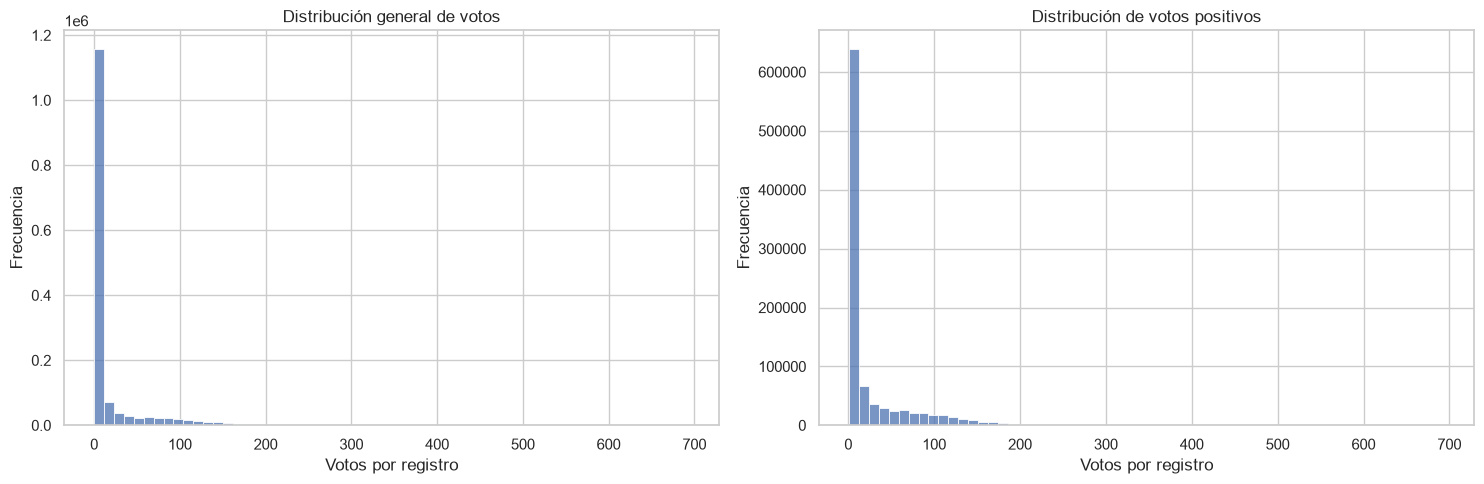

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

sns.histplot(
    data=df_preconteo,
    x="votos",
    bins=60,
    ax=axes[0]
)

axes[0].set_title("Distribución general de votos")
axes[0].set_xlabel("Votos por registro")
axes[0].set_ylabel("Frecuencia")

sns.histplot(
    x=df_preconteo.loc[
        df_preconteo["votos"] > 0,
        "votos"
    ],
    bins=60,
    ax=axes[1]
)

axes[1].set_title("Distribución de votos positivos")
axes[1].set_xlabel("Votos por registro")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

In [56]:
frecuencias_votos = (
    df_preconteo["votos"]
    .value_counts()
    .rename_axis("votos")
    .reset_index(name="frecuencia")
)

frecuencias_votos["porcentaje"] = (
    frecuencias_votos["frecuencia"]
    / len(df_preconteo)
    * 100
)

display(
    frecuencias_votos
    .head(20)
    .round(3)
)

,votos,frecuencia,porcentaje
0,0,527421,35.648
1,1,237402,16.046
2,2,114083,7.711
3,3,74591,5.042
4,4,53288,3.602
5,5,39904,2.697
6,6,30358,2.052
7,7,23502,1.589
8,8,18471,1.248
9,9,14759,0.998


### Interpretación de la distribución de votos

El análisis descriptivo de los 1.479.506 registros del preconteo evidencia una distribución marcadamente asimétrica hacia la derecha. La media de 16,207 votos supera considerablemente la mediana de 1 voto, lo que indica una concentración de observaciones en valores pequeños y una extensión de la distribución hacia valores elevados.

Se identificaron 527.421 registros con cero votos, equivalentes al 35,648 % del conjunto de datos. Este hallazgo confirma que el archivo contiene registros explícitos con valor cero, por lo que la ausencia de una combinación mesa-opción no puede interpretarse automáticamente como un resultado de cero votos.

El 75 % de los registros presenta ocho votos o menos, mientras que los percentiles 95 y 99 corresponden a 104 y 164 votos, respectivamente. El máximo observado es de 694 votos.

La distribución agregada combina diferentes candidaturas y categorías electorales, cuyas magnitudes de votación pueden variar sustancialmente. Por esta razón, los valores elevados no deben considerarse anomalías únicamente por su posición en la distribución global.

Los resultados justifican profundizar en el comportamiento de los votos por opción electoral y posteriormente por mesa, conservando la distinción entre valores observados, registros explícitos con cero y opciones ausentes.

In [57]:
# Trabajar únicamente con las 13 candidaturas identificadas
df_candidaturas = df_preconteo[
    df_preconteo["candidato"].isin(
        catalogo_electoral["candidato"]
    )
].copy()

# Incorporar nombres sin modificar los datos originales
df_candidaturas = df_candidaturas.merge(
    catalogo_electoral[
        ["lista_partido", "candidato", "nombre_completo"]
    ],
    on=["lista_partido", "candidato"],
    how="left",
    validate="many_to_one"
)

resumen_candidaturas = (
    df_candidaturas
    .groupby(["candidato", "nombre_completo"])
    .agg(
        registros=("votos", "size"),
        votos_totales=("votos", "sum"),
        media=("votos", "mean"),
        mediana=("votos", "median"),
        desviacion=("votos", "std"),
        maximo=("votos", "max"),
        registros_cero=("votos", lambda x: (x == 0).sum())
    )
    .reset_index()
)

resumen_candidaturas["porcentaje_ceros"] = (
    resumen_candidaturas["registros_cero"]
    / resumen_candidaturas["registros"]
    * 100
)

display(
    resumen_candidaturas
    .sort_values("candidato")
    .round(2)
)

,candidato,nombre_completo,registros,votos_totales,media,mediana,desviacion,maximo,registros_cero,porcentaje_ceros
0,001,IVÁN CEPEDA CASTRO,121967,9688361,79.43,75.0,43.53,325,100,0.08
1,002,CLAUDIA LÓPEZ,106109,225517,2.13,1.0,3.14,245,34606,32.61
2,003,RAÚL SANTIAGO BOTERO JARAMILLO,102972,206140,2.00,1.0,2.36,179,23425,22.75
3,004,ABELARDO DE LA ESPRIELLA,121597,10361499,85.21,77.0,53.01,694,260,0.21
4,005,ÓSCAR MAURICIO LIZCANO ARANGO,78894,53839,0.68,0.0,1.73,136,46567,59.02
5,006,MIGUEL URIBE LONDOÑO,73312,28657,0.39,0.0,0.73,60,50846,69.36
6,007,SONDRA MACOLLINS GARVIN PINTO,69947,19889,0.28,0.0,0.60,25,53296,76.19
7,008,ROY LEONARDO BARRERAS MONTEALEGRE,67626,14108,0.21,0.0,0.51,18,55423,81.96
8,009,CARLOS EDUARDO CAICEDO OMAR,65201,12694,0.19,0.0,0.54,24,54686,83.87
9,010,GUSTAVO MATAMOROS CAMACHO,63261,5627,0.09,0.0,0.44,29,58454,92.40


### Distribución de votos por candidatura

El análisis desagregado de las 13 candidaturas evidencia una heterogeneidad considerable en las distribuciones de votos registrados por mesa.

Las candidaturas presentan diferencias tanto en sus medidas de tendencia central como en la proporción de registros con cero votos. Las medianas observadas oscilan entre 0 y 77 votos, mientras que los porcentajes de registros con cero varían entre 0,08 % y 92,40 %.

Adicionalmente, la cantidad de registros disponibles difiere entre candidaturas. Esta característica debe considerarse al interpretar las estadísticas, ya que los registros presentes no necesariamente constituyen el mismo conjunto de mesas para todas las opciones electorales.

Los resultados indican que la distribución agregada de votos combina poblaciones con comportamientos estadísticos distintos. Por consiguiente, la identificación de observaciones atípicas mediante umbrales globales podría resultar inadecuada, dado que valores habituales para una candidatura podrían ser poco frecuentes para otra.

En esta fase de entendimiento de los datos, estos hallazgos justifican explorar las distribuciones por candidatura y estudiar la relación entre presencia de registros, valores explícitos de cero y magnitudes de votación. No se atribuyen causas a las diferencias observadas ni se interpretan como evidencia de irregularidades electorales.

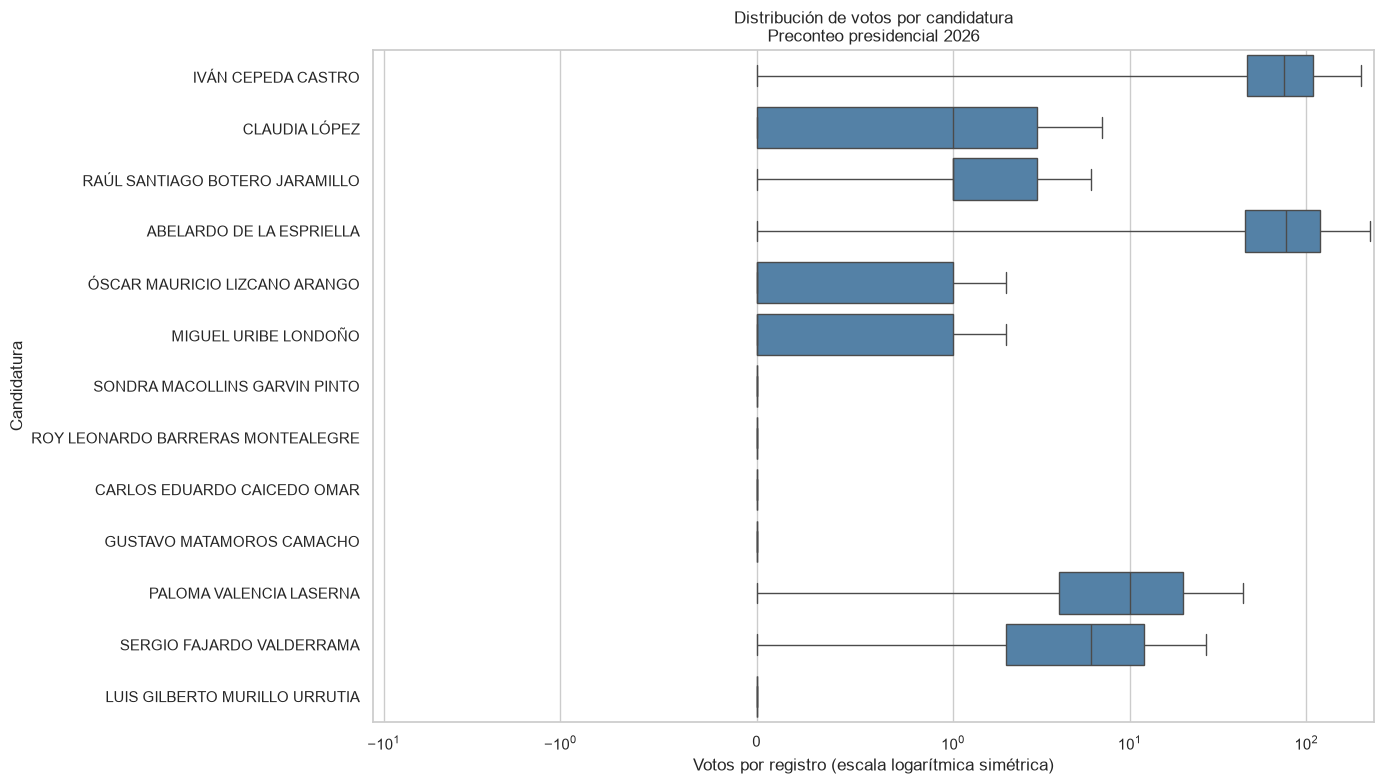

In [58]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ordenar por código de candidatura
orden_candidatos = (
    catalogo_electoral
    .sort_values("candidato")["nombre_completo"]
    .tolist()
)

plt.figure(figsize=(14, 8))

sns.boxplot(
    data=df_candidaturas,
    x="votos",
    y="nombre_completo",
    order=orden_candidatos,
    showfliers=False,
    color="steelblue"
)

plt.xscale("symlog", linthresh=1)

plt.title(
    "Distribución de votos por candidatura\n"
    "Preconteo presidencial 2026"
)

plt.xlabel("Votos por registro (escala logarítmica simétrica)")
plt.ylabel("Candidatura")

plt.tight_layout()
plt.show()

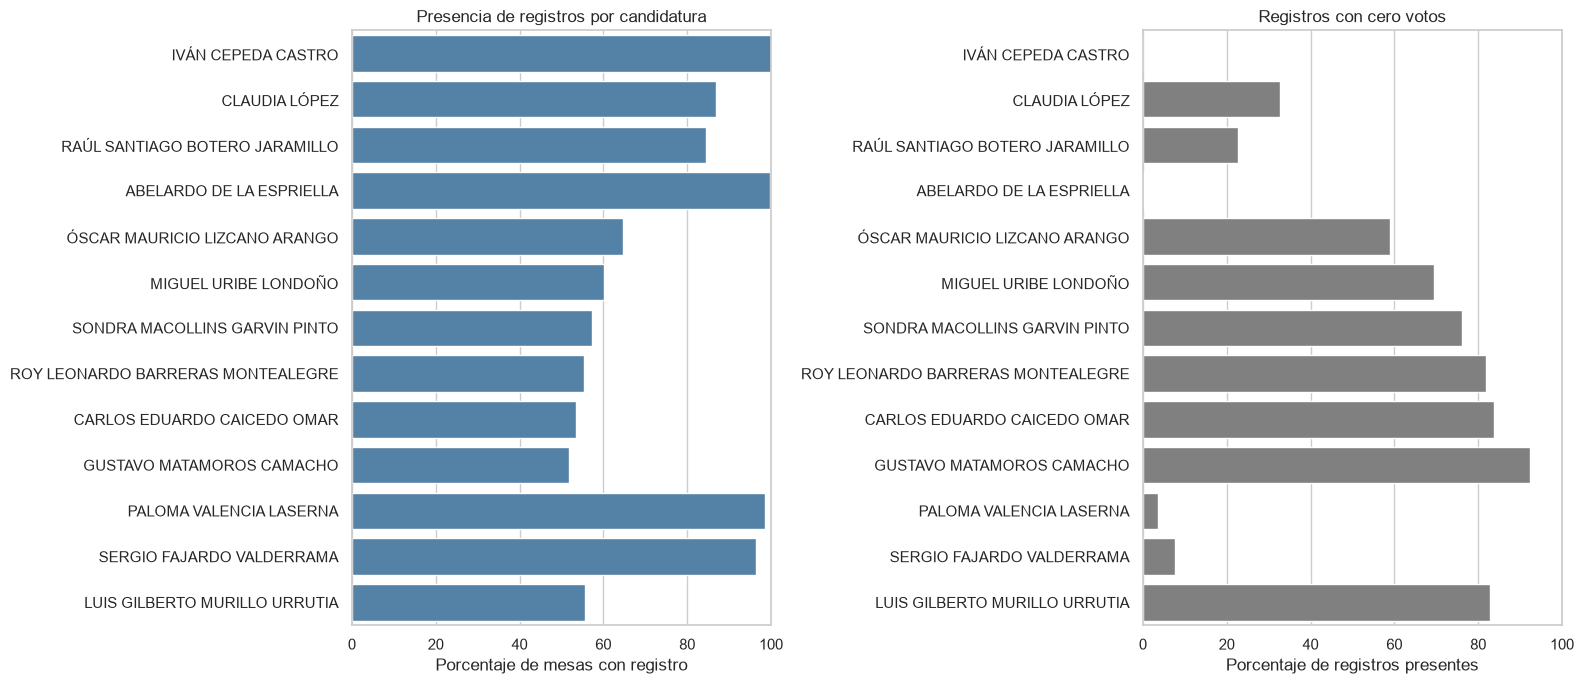

In [59]:
total_mesas = 122020

grafico_candidaturas = resumen_candidaturas.copy()

grafico_candidaturas["porcentaje_presencia"] = (
    grafico_candidaturas["registros"]
    / total_mesas * 100
)

grafico_candidaturas = (
    grafico_candidaturas
    .sort_values("candidato")
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=grafico_candidaturas,
    x="porcentaje_presencia",
    y="nombre_completo",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("Presencia de registros por candidatura")
axes[0].set_xlabel("Porcentaje de mesas con registro")
axes[0].set_ylabel("")
axes[0].set_xlim(0, 100)

sns.barplot(
    data=grafico_candidaturas,
    x="porcentaje_ceros",
    y="nombre_completo",
    ax=axes[1],
    color="gray"
)

axes[1].set_title("Registros con cero votos")
axes[1].set_xlabel("Porcentaje de registros presentes")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 100)

plt.tight_layout()
plt.show()

### Distribución de votos agregados por mesa electoral

La exploración anterior permitió identificar diferencias significativas en las distribuciones de votos entre candidaturas, así como variaciones en la presencia de registros y en la frecuencia de valores explícitos de cero.

En esta sección se adopta la mesa electoral como unidad de análisis, definida mediante la combinación de departamento, municipio, zona, puesto y mesa.

Para cada unidad se calculará la suma de los votos registrados en las distintas opciones electorales. Esta agregación permitirá describir la distribución de las magnitudes de votación observadas entre mesas y examinar la presencia de valores extremos.

Debe tenerse en cuenta que la suma de votos registrados no equivale necesariamente al número de sufragantes ni a la participación electoral, ya que todavía no se ha verificado la completitud de todas las categorías electorales ni su correspondencia con los indicadores oficiales de votación.

In [60]:
# Verificar las variables necesarias
columnas_requeridas = [
    "opciones_presentes",
    "suma_votos_registrados",
    "registros_cero"
]

assert all(
    columna in resumen_mesas.columns
    for columna in columnas_requeridas
)

votos_mesa = resumen_mesas["suma_votos_registrados"]

estadisticas_mesas = pd.Series({
    "Total de mesas": len(resumen_mesas),
    "Votos registrados (suma global)": votos_mesa.sum(),
    "Mínimo": votos_mesa.min(),
    "Máximo": votos_mesa.max(),
    "Media": votos_mesa.mean(),
    "Mediana": votos_mesa.median(),
    "Desviación estándar": votos_mesa.std(),
    "Percentil 1": votos_mesa.quantile(0.01),
    "Percentil 5": votos_mesa.quantile(0.05),
    "Percentil 25": votos_mesa.quantile(0.25),
    "Percentil 75": votos_mesa.quantile(0.75),
    "Percentil 95": votos_mesa.quantile(0.95),
    "Percentil 99": votos_mesa.quantile(0.99),
    "Mesas con suma cero": (votos_mesa == 0).sum(),
})

display(
    estadisticas_mesas
    .to_frame("Valor")
    .round(2)
)

,Valor
Total de mesas,122020.00
Votos registrados (suma global),23978304.00
Mínimo,0.00
Máximo,942.00
Media,196.51
Mediana,205.00
Desviación estándar,71.70
Percentil 1,16.00
Percentil 5,56.00
Percentil 25,154.00


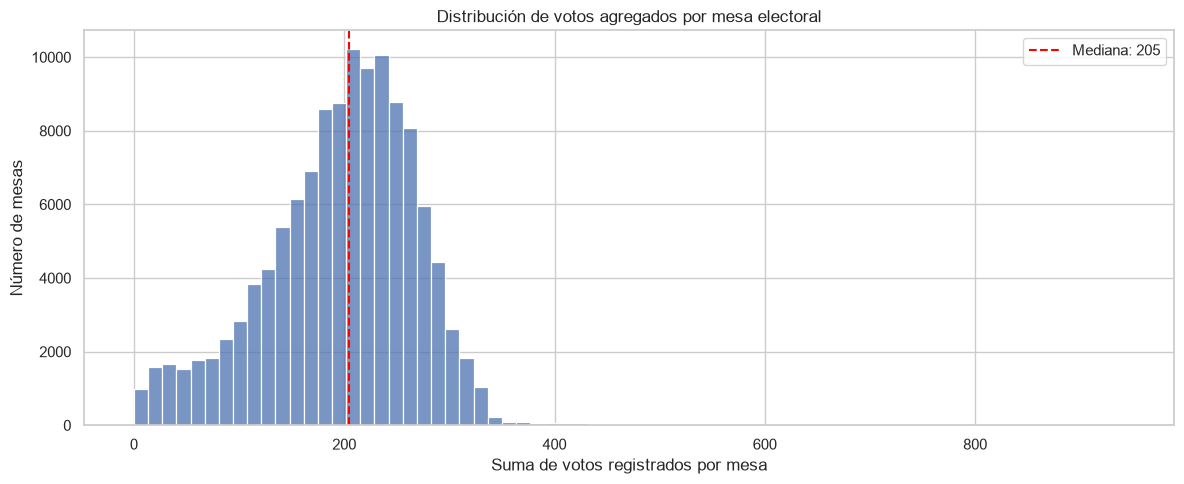

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(12, 5))

sns.histplot(
    data=resumen_mesas,
    x="suma_votos_registrados",
    bins=70,
    ax=ax
)

ax.axvline(
    votos_mesa.median(),
    color="red",
    linestyle="--",
    label=f"Mediana: {votos_mesa.median():.0f}"
)

ax.set_title(
    "Distribución de votos agregados por mesa electoral"
)
ax.set_xlabel("Suma de votos registrados por mesa")
ax.set_ylabel("Número de mesas")
ax.legend()

plt.tight_layout()
plt.show()

In [62]:
columnas_resultado = (
    columnas_mesa
    + [
        "opciones_presentes",
        "suma_votos_registrados",
        "registros_cero"
    ]
)

print("Mesas con las mayores sumas de votos registrados")

display(
    resumen_mesas
    .nlargest(15, "suma_votos_registrados")[
        columnas_resultado
    ]
)

print("Mesas con las menores sumas de votos registrados")

display(
    resumen_mesas
    .nsmallest(15, "suma_votos_registrados")[
        columnas_resultado
    ]
)

Mesas con las mayores sumas de votos registrados


,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados,registros_cero
120275,88,360,35,81,000001,8,942,0
120760,88,360,57,85,000001,16,663,10
119677,88,355,05,85,000009,16,639,8
120758,88,360,57,83,000001,16,635,8
120679,88,360,55,84,000001,9,625,2
120830,88,360,59,81,000003,16,615,9
120503,88,360,40,83,000007,16,603,8
118924,88,285,05,84,000001,9,597,1
118925,88,285,05,85,000001,10,596,1
120759,88,360,57,84,000001,16,593,9


Mesas con las menores sumas de votos registrados


,departamento,municipio,zona,puesto,mesa,opciones_presentes,suma_votos_registrados,registros_cero
67657,17,001,99,25,000001,1,0,1
67664,17,001,99,33,000001,1,0,1
67868,17,010,99,17,000001,1,0,1
67930,17,011,99,40,000001,1,0,1
67931,17,011,99,41,000001,1,0,1
68221,17,025,99,17,000001,1,0,1
118413,88,130,05,81,000001,1,0,1
118414,88,130,05,82,000001,1,0,1
118415,88,130,05,83,000001,1,0,1
118416,88,130,05,84,000001,1,0,1


## Referencias bibliográficas


Chandola, V., Banerjee, A., & Kumar, V. (2009). Anomaly detection: A survey. ACM Computing Surveys, 41(3), Article 15. https://doi.org/10.1145/1541880.1541882

Han, S., Hu, X., Huang, H., Jiang, M., & Zhao, Y. (2022). ADBench: Anomaly detection benchmark. Advances in Neural Information Processing Systems, 35. https://papers.neurips.cc/paper_files/paper/2022/hash/cf93972b116ca5268827d575f2cc226b-Abstract-Datasets_and_Benchmarks.html

Zhang, M., Alvarez, R. M., & Levin, I. (2019). Election forensics: Using machine learning and synthetic data for possible election anomaly detection. PLOS ONE, 14(10), Article e0223950. https://doi.org/10.1371/journal.pone.0223950


Constitución Política de Colombia [Const.]. (1991). Artículo 265. https://www.cne.gov.co/leyes-y-actos-legislativos-cne
Registraduría Nacional del Estado Civil. (s. f.). Cartilla de escrutinios. https://www.registraduria.gov.co/IMG/pdf/cartilla_escrutinios.pdf
Registraduría Nacional del Estado Civil. (2026). Estas son las diferencias entre los resultados de la transmisión y el escrutinio oficial. https://wapp.registraduria.gov.co/electoral/2026/presidente-de-la-republica/documentos/narrativas/diferencias_transmision_escrutinio.pdf

## **Créditos**
---

* **Profesor:** [Fabio Augusto Gonzalez](https://dis.unal.edu.co/~fgonza/)
* **Asistente docente :**
  * [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Diseño de imágenes:**
    - [Rosa Alejandra Superlano Esquibel](https://www.linkedin.com/in/alejandrasuperlano/).
* **Coordinador de virtualización:**
    - [Edder Hernández Forero](https://www.linkedin.com/in/edder-hernandez-forero-28aa8b207/).

**Universidad Nacional de Colombia** - *Facultad de Ingeniería*